### Challenge 2: Make the Quantum Coin Biased

In [1]:
# Step 1: Import required libraries and initialize simulator
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Initialize simulator backend
simulator = AerSimulator()
print("AerSimulator initialized successfully.")


AerSimulator initialized successfully.


In [5]:
qc = QuantumCircuit(1)
theta = np.pi / 3
qc.ry(theta, 0)
qc.measure_all()
# Execute the circuit for 100 shots using AerSimulator
backend = AerSimulator()
# Map and run via simulator
result = backend.run(qc, shots=100).result()
# Observe the number of 0 and 1 outcomes
counts = result.get_counts()
print("Measurement outcomes (100 shots):", counts)
# Display the results using a histogram
plot_histogram(counts)
plt.show()

Measurement outcomes (100 shots): {'0': 74, '1': 26}


---
## Bonus Experiment: 
### Biased Toward 0 ($P(0) > P(1)$)

### Prediction Before Execution
- **Theoretical $P(0)$:** $\frac{2+\sqrt{2}}{4} \approx 85.36\%$
- **Theoretical $P(1)$:** $\frac{2-\sqrt{2}}{4} \approx 14.64\%$
- **Predicted counts for 100 shots:**
  - Expected `0` count: $\approx 85$
  - Expected `1` count: $\approx 15$
  - Expected statistical variation: Within $85 \pm 2\sigma \approx 85 \pm 7$ shots.


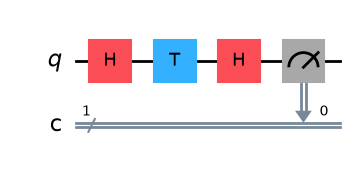

Experiment A (Biased toward 0) Measurement Results (100 shots): {'1': 13, '0': 87}


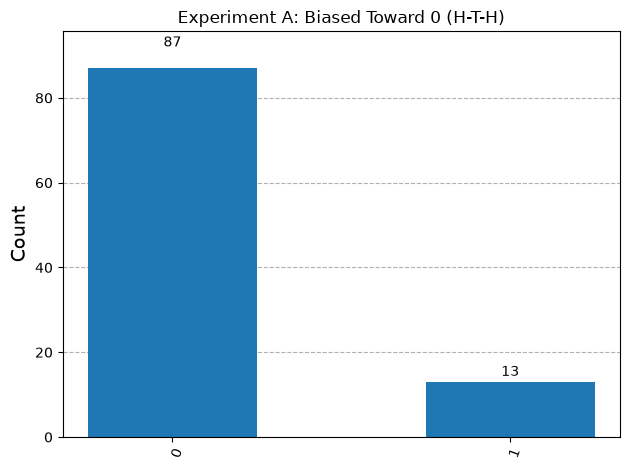

In [2]:
qc_bias_0 = QuantumCircuit(1, 1, name="Biased toward 0 (H-T-H)")

# Apply 3 gates: H -> T -> H
qc_bias_0.h(0)
qc_bias_0.t(0)
qc_bias_0.h(0)

# Measure
qc_bias_0.measure(0, 0)

# Display circuit diagram
display(qc_bias_0.draw("mpl"))

# Execute for exactly 100 shots
shots = 100
job_a = simulator.run(qc_bias_0, shots=shots)
result_a = job_a.result()
counts_bias_0 = result_a.get_counts()

print("Experiment A (Biased toward 0) Measurement Results (100 shots):", counts_bias_0)
plot_histogram(counts_bias_0, title="Experiment A: Biased Toward 0 (H-T-H)")



## Biased Toward 1 ($P(1) > P(0)$)

### Prediction Before Execution
- **Theoretical $P(0)$:** $\frac{2-\sqrt{2}}{4} \approx 14.64\%$
- **Theoretical $P(1)$:** $\frac{2+\sqrt{2}}{4} \approx 85.36\%$
- **Predicted counts for 100 shots:**
  - Expected `0` count: $\approx 15$
  - Expected `1` count: $\approx 85$
  - Expected statistical variation: Within $85 \pm 2\sigma \approx 85 \pm 7$ shots.


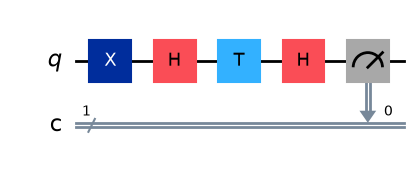

Experiment B (Biased toward 1) Measurement Results (100 shots): {'1': 85, '0': 15}


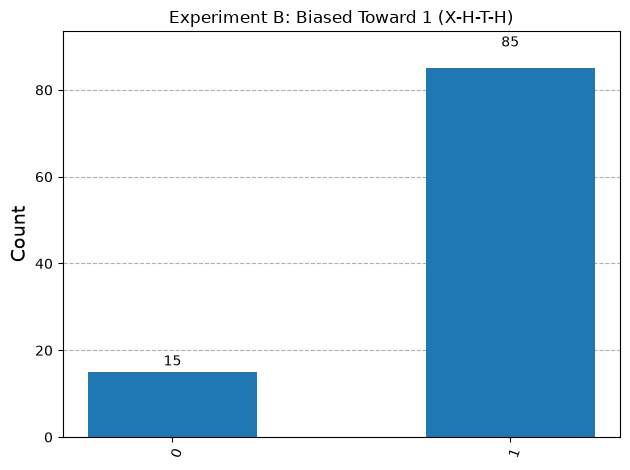

In [3]:
qc_bias_1 = QuantumCircuit(1, 1, name="Biased toward 1 (X-H-T-H)")

# Apply 4 gates: X -> H -> T -> H
qc_bias_1.x(0)
qc_bias_1.h(0)
qc_bias_1.t(0)
qc_bias_1.h(0)

# Measure
qc_bias_1.measure(0, 0)

# Display circuit diagram
display(qc_bias_1.draw("mpl"))

# Execute for exactly 100 shots
job_b = simulator.run(qc_bias_1, shots=shots)
result_b = job_b.result()
counts_bias_1 = result_b.get_counts()

print("Experiment B (Biased toward 1) Measurement Results (100 shots):", counts_bias_1)
plot_histogram(counts_bias_1, title="Experiment B: Biased Toward 1 (X-H-T-H)")


---
## Comparison of the Two Biased Distributions
Here we plot the measurement results of Experiment A and Experiment B together to directly compare the reversed bias.


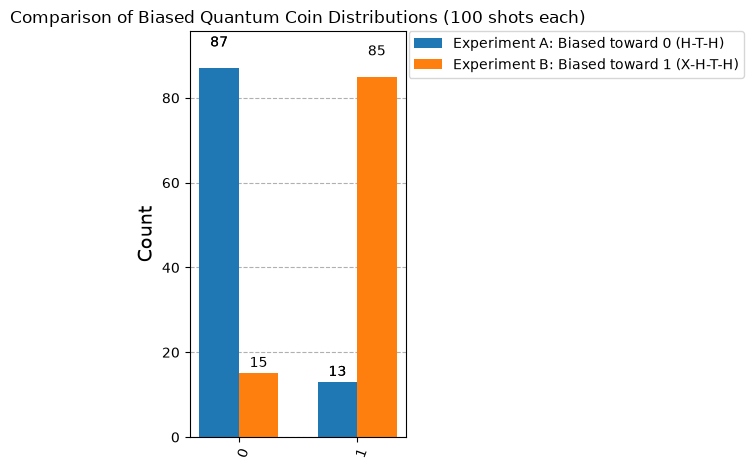

In [4]:
plot_histogram(
    [counts_bias_0, counts_bias_1],
    legend=["Experiment A: Biased toward 0 (H-T-H)", "Experiment B: Biased toward 1 (X-H-T-H)"],
    title="Comparison of Biased Quantum Coin Distributions (100 shots each)"
)


---
## Analysis and Comparison of Results

| Experiment | Gate Sequence | Gate Count | Predicted $P(0)$ | Predicted $P(1)$ | Dominant Outcome | Observed Counts (100 shots) |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Bonus A** | $H \rightarrow T \rightarrow H$ | 3 gates ($\le 4$) | $85.36\%$ | $14.64\%$ | `0` | Skewed heavily toward 0 |
| **Bonus B** | $X \rightarrow H \rightarrow T \rightarrow H$ | 4 gates ($\le 4$) | $14.64\%$ | $85.36\%$ | `1` | Skewed heavily toward 1 |

### Explanation of How the Gates Modified the Distribution
1. **From Fair to Biased:** A single Hadamard gate sets the phase difference to $0$ and yields equal magnitudes for $|0\rangle$ and $|1\rangle$. Inserting the $T$ gate between two Hadamard gates introduces a complex phase shift of $\pi/4$ ($45^\circ$). When the second Hadamard gate recombines the basis vectors, quantum interference takes place:
   - For outcome $0$, the paths interfere **constructively**, boosting the probability from $50\%$ to $85.36\%$.
   - For outcome $1$, the paths interfere **destructively**, reducing the probability from $50\%$ to $14.64\%$.
2. **Reversing the Bias:** Inserting a preparatory $X$ gate flips the input state to $|1\rangle$. The relative minus sign introduced by $H|1\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}}$ inverts the interference pattern during the second Hadamard gate, causing destructive interference at $0$ and constructive interference at $1$.
3. **Finite Sampling (100 shots):** The observed counts closely match the theoretical expectation of $\approx 85/15$ within expected statistical shot noise.


---
## Challenge Question

### "How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?"

In quantum mechanics, a qubit's state is described by a linear combination of basis states:
$$|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$$
where $\alpha$ and $\beta$ are complex numbers known as **probability amplitudes**, satisfying the normalization condition $|lpha|^2 + |\beta|^2 = 1$.

According to **Born's rule**, when a qubit is measured in the computational basis:
- The probability of obtaining outcome $0$ is $P(0) = |\alpha|^2$.
- The probability of obtaining outcome $1$ is $P(1) = |\beta|^2$.

Quantum gates modify these measurement probabilities through two fundamental mechanisms:

1. **State Rotation on the Bloch Sphere:**
   Every single-qubit quantum gate corresponds to a unitary transformation, geometrically represented as a rotation of the state vector on the three-dimensional Bloch sphere. The probability of measuring $0$ is determined solely by the state's polar angle $\theta$ from the $+Z$ axis:
   $$P(0) = \cos^2\left(\frac{\theta}{2}\right), \quad P(1) = \sin^2\left(\frac{\theta}{2}\right)$$
   Gates like $R_y(\theta)$ directly rotate the vector towards or away from the North pole ($|0\rangle$), tuning the measurement probabilities continuously.

2. **Quantum Phase and Interference:**
   Even when gates do not change the absolute magnitudes of the amplitudes directly (such as phase gates $Z$, $S$, and $T$, which only change the relative phase angle $\phi$), combining them with basis-changing gates like the Hadamard ($H$) converts relative phases into amplitude interference:
   $$H\left(\frac{|0\rangle + e^{i\phi}|1\rangle}{\sqrt{2}}\right) = \cos\left(\frac{\phi}{2}\right)e^{i\phi/2}|0\rangle - i\sin\left(\frac{\phi}{2}\right)e^{i\phi/2}|1\rangle$$
   Depending on the relative phase $\phi$, computational paths interfere **constructively** (amplifying the probability of an outcome) or **destructively** (diminishing the probability of an outcome).

In conclusion, quantum gates manipulate the **amplitudes** and **relative phases** of the quantum state. Through **constructive and destructive interference**, gates redistribute probability between $|0\rangle$ and $|1\rangle$, allowing us to program any desired measurement bias into the quantum coin.
